# Chapter 7: Variation-Based Linearization, State-Constrained Controllability & LTV-LQR

This notebook accompanies **Chapter 7** of *A Lie-Interpretation of Robotics and Control* and implements the variation-based linearization, state-constrained controllability verification, and finite-horizon LTV-LQR synthesis from:
- Wu & Sreenath (2015), *Variation-based Linearization of Nonlinear Systems Evolving on $SO(3)$ and $S^2$*, IEEE Access ([PDF](https://hybrid-robotics.berkeley.edu/publications/Access2015_VariationLinearization.pdf))
- Kotaru, Wu, & Sreenath (2017), *Differential-Flatness and Control of Quadrotor(s) with a Payload Suspended through Flexible Cable(s)* ([arXiv:1711.04895](https://arxiv.org/pdf/1711.04895))

We cover:
1. **Lie-algebra & manifold utilities** on $SO(3)$ and $S^2$ (`hat`, `vee`, $\exp$, $\log$).
2. **Spherical Pendulum on $S^2$**: derivation of $(A(t), B(t), C(t))$, verification of $\frac{d}{dt}(C s) = 0$ invariance and state-constrained controllability $\text{rank}([B, \dot{B} + AB]) = 4$, backward Riccati ODE integration, and nonlinear closed-loop tracking from a $50^\circ$ initial error.
3. **3D Pendulum on $SO(3)$**: derivation of $(A(t), B(t))$, controllability rank verification ($\text{rank}([B, \dot{B} + AB]) = 6$), backward Riccati ODE integration, and nonlinear closed-loop tracking from a $60^\circ$ initial error.


In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

def hat(x):
    """Hat map (.)^ : R^3 -> so(3) satisfying hat(x) @ y = np.cross(x, y)."""
    x = np.asarray(x, dtype=float)
    return np.array([
        [0.0, -x[2], x[1]],
        [x[2], 0.0, -x[0]],
        [-x[1], x[0], 0.0]
    ])

def vee(M):
    """Vee map (.)^v : so(3) -> R^3."""
    return np.array([M[2, 1], M[0, 2], M[1, 0]], dtype=float)

def exp_so3(phi):
    """Rodrigues' formula for exp(hat(phi)) on SO(3)."""
    phi = np.asarray(phi, dtype=float)
    theta = np.linalg.norm(phi)
    if theta < 1e-10:
        return np.eye(3) + hat(phi) + 0.5 * (hat(phi) @ hat(phi))
    K = hat(phi / theta)
    return np.eye(3) + np.sin(theta) * K + (1.0 - np.cos(theta)) * (K @ K)

def log_so3(R):
    """Logarithm map SO(3) -> R^3 (returns eta such that exp(hat(eta)) = R)."""
    cos_theta = np.clip(0.5 * (np.trace(R) - 1.0), -1.0, 1.0)
    theta = np.arccos(cos_theta)
    if theta < 1e-8:
        return 0.5 * vee(R - R.T)
    if np.pi - theta < 1e-6:
        # Near pi, extract axis from symmetric part
        eigvals, eigvecs = np.linalg.eigh(R)
        idx = np.argmin(np.abs(eigvals - 1.0))
        axis = eigvecs[:, idx]
        return theta * axis
    return (theta / (2.0 * np.sin(theta))) * vee(R - R.T)

def log_s2(qd, q):
    """Tangent vector xi in T_{qd} S^2 such that exp(hat(xi)) @ qd = q and xi . qd = 0."""
    dot = np.clip(np.dot(qd, q), -1.0, 1.0)
    theta = np.arccos(dot)
    if theta < 1e-9:
        return np.cross(qd, q)
    cross = np.cross(qd, q)
    n = np.linalg.norm(cross)
    if n < 1e-12:
        # Antipodal case: pick any orthogonal unit vector
        e = np.array([1.0, 0.0, 0.0]) if abs(qd[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
        axis = np.cross(qd, e)
        axis /= np.linalg.norm(axis)
        return theta * axis
    return (theta / n) * cross

print("Lie algebra utilities initialized successfully.")


Lie algebra utilities initialized successfully.


## Part A: Spherical Pendulum on $S^2$

The spherical pendulum has configuration $q \in S^2$ and angular velocity $\omega \in \mathbb{R}^3$ satisfying $q \cdot \omega = 0$:
$$\dot{q} = \omega \times q, \qquad \dot{\omega} = \frac{g}{l} e_3^\wedge q + \frac{1}{m l^2}(I_3 - q q^T) u$$

Using variations $\delta q = \xi \times q_d = -q_d^\wedge \xi$ ($\xi \cdot q_d = 0$) and $\delta \omega$ satisfying $(\xi \times q_d)\cdot \omega_d + q_d \cdot \delta \omega = 0$, the linearized state $s = [\xi^T, \delta \omega^T]^T \in \mathbb{R}^6$ obeys:
$$\dot{s} = A(t) s + B(t) \delta u, \qquad C(t) s = 0$$
with:
$$C(t) = \begin{bmatrix} q_d^T & 0_{1\times 3} \\ (q_d^\wedge \omega_d)^T & q_d^T \end{bmatrix}, \quad B(t) = \begin{bmatrix} 0_{3\times 3} \\ \frac{1}{ml^2}(I_3 - q_d q_d^T) \end{bmatrix}$$


In [2]:
# Physical parameters for Spherical Pendulum
m_sp = 1.0
l_sp = 1.0
g = 9.81
e3 = np.array([0.0, 0.0, 1.0])

def spherical_ref(t):
    """Smooth time-varying reference trajectory on S^2 (conical + figure-8 modulation)."""
    # Parameterize via smooth angles theta(t), phi(t)
    th = 0.45 + 0.15 * np.sin(1.2 * t)
    dth = 0.15 * 1.2 * np.cos(1.2 * t)
    ddth = -0.15 * (1.2**2) * np.sin(1.2 * t)

    ph = 0.8 * t + 0.2 * np.sin(0.6 * t)
    dph = 0.8 + 0.2 * 0.6 * np.cos(0.6 * t)
    ddph = -0.2 * (0.6**2) * np.sin(0.6 * t)

    st, ct = np.sin(th), np.cos(th)
    sp, cp = np.sin(ph), np.cos(ph)

    # Hanging-down spherical coordinates: q = [st*cp, st*sp, -ct]
    qd = np.array([st * cp, st * sp, -ct])

    dqd = np.array([
        dth * ct * cp - st * sp * dph,
        dth * ct * sp + st * cp * dph,
        dth * st
    ])

    ddqd = np.array([
        ddth * ct * cp - dth**2 * st * cp - 2 * dth * ct * sp * dph - st * cp * dph**2 - st * sp * ddph,
        ddth * ct * sp - dth**2 * st * sp + 2 * dth * ct * cp * dph - st * sp * dph**2 + st * cp * ddph,
        ddth * st + dth**2 * ct
    ])

    # Since qd . dqd = 0 and qd_dot = omega_d x qd with qd . omega_d = 0:
    # omega_d = qd x dqd, and domega_d = qd x ddqd
    omega_d = np.cross(qd, dqd)
    domega_d = np.cross(qd, ddqd)
    ud = m_sp * (l_sp**2) * (domega_d - (g / l_sp) * np.cross(e3, qd))
    return qd, dqd, omega_d, domega_d, ud

def spherical_LTV(t):
    qd, dqd, omega_d, domega_d, ud = spherical_ref(t)
    P_perp = np.eye(3) - np.outer(qd, qd)

    A11 = hat(omega_d)
    A12 = P_perp
    # delta(e3^ q) = -e3^ qd^ xi
    # delta((I - q q^T) u) = - (delta q (q_d^T u_d) + q_d (delta q^T u_d))
    # with delta q = -qd^ xi:
    A21 = -(g / l_sp) * (hat(e3) @ hat(qd)) + (1.0 / (m_sp * l_sp**2)) * (np.dot(qd, ud) * np.eye(3) + np.outer(qd, ud)) @ hat(qd)
    A22 = np.zeros((3, 3))

    A = np.block([[A11, A12], [A21, A22]])
    B = np.vstack([np.zeros((3, 3)), (1.0 / (m_sp * l_sp**2)) * P_perp])
    C = np.block([[qd.reshape(1, 3), np.zeros((1, 3))],
                  [(hat(qd) @ omega_d).reshape(1, 3), qd.reshape(1, 3)]])
    return A, B, C

# 1. Verify d/dt(C s) = 0 invariance and controllability rank across t in [0, 10]
rng = np.random.default_rng(42)
dt_fd = 1e-6
max_invariance_err = 0.0
min_rank_sp = 999

for t_chk in np.linspace(0.0, 10.0, 50):
    A, B, C = spherical_LTV(t_chk)
    Ap, Bp, Cp = spherical_LTV(t_chk + dt_fd)
    Am, Bm, Cm = spherical_LTV(t_chk - dt_fd)
    Cdot = (Cp - Cm) / (2 * dt_fd)
    Bdot = (Bp - Bm) / (2 * dt_fd)

    # Nullspace basis of C(t)
    _, _, Vt = np.linalg.svd(C)
    N_basis = Vt[2:, :].T  # 6x4
    for _ in range(5):
        s_null = N_basis @ rng.standard_normal(4)
        du_rand = rng.standard_normal(3)
        dCs_dt = (C @ A + Cdot) @ s_null + (C @ B) @ du_rand
        max_invariance_err = max(max_invariance_err, np.linalg.norm(dCs_dt))

    # Operator s(B) = Bdot + A @ B
    sB = Bdot + A @ B
    Q_ctrl = np.hstack([B, sB])
    rank_c = np.linalg.matrix_rank(Q_ctrl, tol=1e-7)
    min_rank_sp = min(min_rank_sp, rank_c)

print(f"Spherical Pendulum max ||d/dt(C s)|| = {max_invariance_err:.3e}")
print(f"Spherical Pendulum min rank([B, Bdot + A B]) = {min_rank_sp} (dim N(C) = 4)")


Spherical Pendulum max ||d/dt(C s)|| = 1.104e-09
Spherical Pendulum min rank([B, Bdot + A B]) = 4 (dim N(C) = 4)


In [3]:
# 2. Solve Finite-Horizon Riccati ODE backwards for Spherical Pendulum
T_sp = 10.0
Q_sp = np.diag([40.0, 40.0, 40.0, 8.0, 8.0, 8.0])
R_sp = 0.5 * np.eye(3)
R_sp_inv = np.linalg.inv(R_sp)
Pf_sp = np.diag([50.0, 50.0, 50.0, 10.0, 10.0, 10.0])

def riccati_rhs_sp(t, P_flat):
    P = P_flat.reshape(6, 6)
    A, B, _ = spherical_LTV(t)
    # Integrate backward: dP/dt = -(A^T P + P A - P B R^-1 B^T P + Q)
    Pdot = -(A.T @ P + P @ A - P @ B @ R_sp_inv @ B.T @ P + Q_sp)
    return Pdot.ravel()

t_eval_sp = np.linspace(T_sp, 0.0, 1001)
sol_ric_sp = solve_ivp(riccati_rhs_sp, (T_sp, 0.0), Pf_sp.ravel(), t_eval=t_eval_sp, rtol=1e-7, atol=1e-9)
t_grid_sp = sol_ric_sp.t[::-1]
P_grid_sp = sol_ric_sp.y[:, ::-1].T.reshape(-1, 6, 6)
P_interp_sp = interp1d(t_grid_sp, P_grid_sp, axis=0, kind='linear', fill_value='extrapolate')

# 3. Closed-loop nonlinear simulation from 50 deg initial error
qd0, _, wd0, _, _ = spherical_ref(0.0)
axis0 = np.cross(qd0, np.array([1.0, 0.3, 0.0]))
axis0 /= np.linalg.norm(axis0)
q0 = exp_so3(np.deg2rad(50.0) * axis0) @ qd0
w0 = wd0 + np.array([0.8, -0.6, 0.0])
w0 = w0 - np.dot(q0, w0) * q0  # enforce q0 . w0 = 0

def sp_state_error(t, q, w):
    qd, _, wd, _, _ = spherical_ref(t)
    xi = log_s2(qd, q)
    dw = w - wd - (np.dot(qd, w - wd) + np.dot(np.cross(xi, qd), wd)) * qd
    return np.concatenate([xi, dw])

def sp_closed_loop_rhs(t, y):
    q = y[:3]
    q = q / np.linalg.norm(q)
    w = y[3:]
    _, _, _, _, ud = spherical_ref(t)
    _, B, _ = spherical_LTV(t)
    P = P_interp_sp(t)
    s = sp_state_error(t, q, w)
    du = -R_sp_inv @ B.T @ P @ s
    u = ud + du
    dq = np.cross(w, q)
    dw = (g / l_sp) * np.cross(e3, q) + (1.0 / (m_sp * l_sp**2)) * (np.eye(3) - np.outer(q, q)) @ u
    return np.concatenate([dq, dw])

t_sim_sp = np.linspace(0.0, T_sp, 1001)
sol_sim_sp = solve_ivp(sp_closed_loop_rhs, (0.0, T_sp), np.concatenate([q0, w0]), t_eval=t_sim_sp, rtol=1e-8, atol=1e-10)

# Collect metrics
att_err_sp = np.zeros(len(t_sim_sp))
vel_err_sp = np.zeros(len(t_sim_sp))
cs_norm_sp = np.zeros(len(t_sim_sp))
u_hist_sp = np.zeros((len(t_sim_sp), 3))
qd_hist_sp = np.zeros((len(t_sim_sp), 3))

for i, t in enumerate(t_sim_sp):
    q = sol_sim_sp.y[:3, i]
    q /= np.linalg.norm(q)
    w = sol_sim_sp.y[3:, i]
    qd, _, wd, _, ud = spherical_ref(t)
    qd_hist_sp[i] = qd
    att_err_sp[i] = np.rad2deg(np.arccos(np.clip(np.dot(qd, q), -1.0, 1.0)))
    vel_err_sp[i] = np.linalg.norm(w - wd)
    _, B, C = spherical_LTV(t)
    s = sp_state_error(t, q, w)
    cs_norm_sp[i] = np.linalg.norm(C @ s)
    u_hist_sp[i] = ud - R_sp_inv @ B.T @ P_interp_sp(t) @ s

print(f"Spherical Pendulum Initial Attitude Error: {att_err_sp[0]:.2f} deg")
print(f"Spherical Pendulum Final Attitude Error:   {att_err_sp[-1]:.4f} deg")
print(f"Spherical Pendulum Final Velocity Error:   {vel_err_sp[-1]:.4e} rad/s")
print(f"Spherical Pendulum Max ||C(t) s(t)||:      {np.max(cs_norm_sp):.3e}")


Spherical Pendulum Initial Attitude Error: 50.00 deg
Spherical Pendulum Final Attitude Error:   0.0000 deg
Spherical Pendulum Final Velocity Error:   1.8530e-09 rad/s
Spherical Pendulum Max ||C(t) s(t)||:      6.942e-16


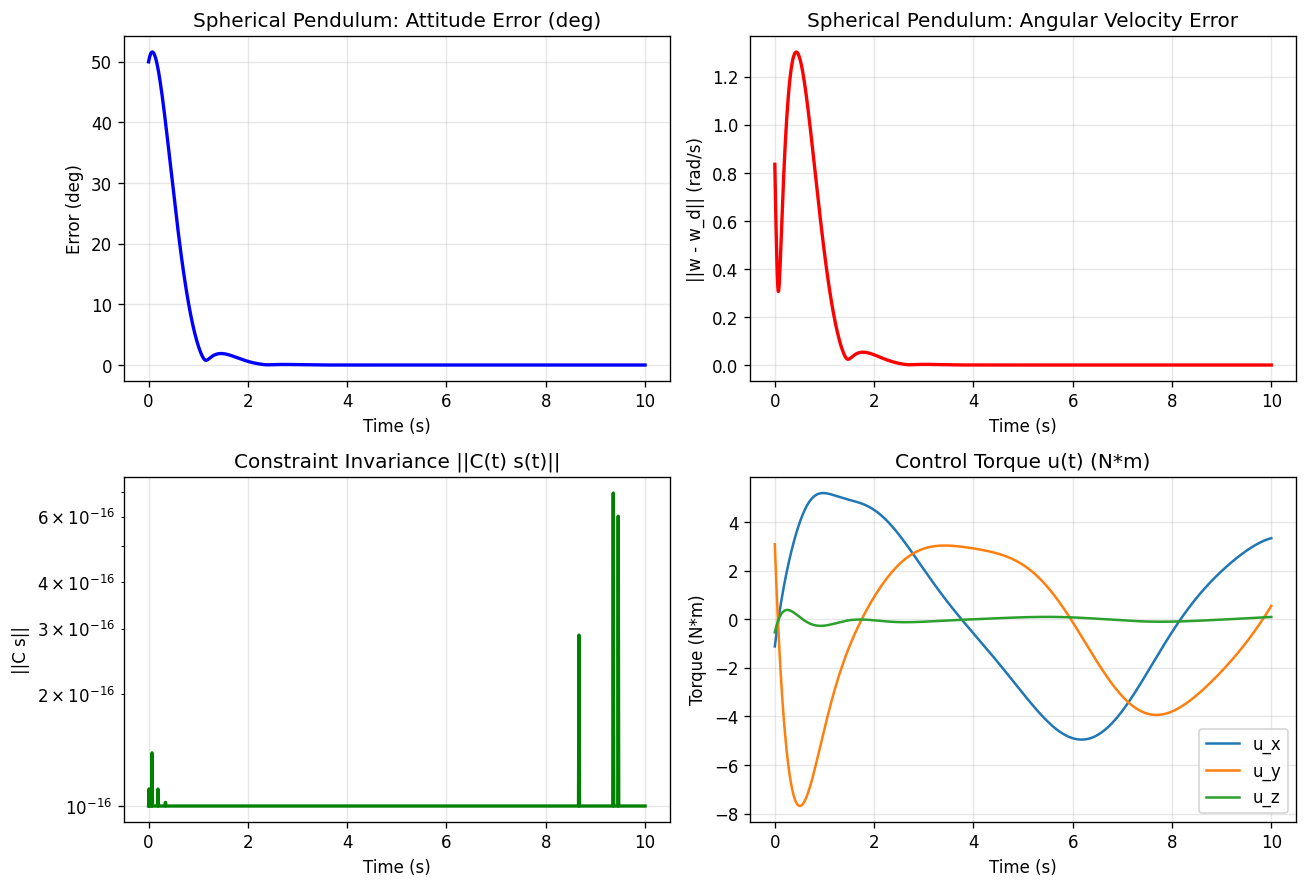

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
axes[0, 0].plot(t_sim_sp, att_err_sp, 'b-', lw=2)
axes[0, 0].set_title('Spherical Pendulum: Attitude Error (deg)')
axes[0, 0].set_xlabel('Time (s)')
axes[0, 0].set_ylabel('Error (deg)')
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(t_sim_sp, vel_err_sp, 'r-', lw=2)
axes[0, 1].set_title('Spherical Pendulum: Angular Velocity Error')
axes[0, 1].set_xlabel('Time (s)')
axes[0, 1].set_ylabel('||w - w_d|| (rad/s)')
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].semilogy(t_sim_sp, np.maximum(cs_norm_sp, 1e-16), 'g-', lw=2)
axes[1, 0].set_title('Constraint Invariance ||C(t) s(t)||')
axes[1, 0].set_xlabel('Time (s)')
axes[1, 0].set_ylabel('||C s||')
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(t_sim_sp, u_hist_sp[:, 0], label='u_x')
axes[1, 1].plot(t_sim_sp, u_hist_sp[:, 1], label='u_y')
axes[1, 1].plot(t_sim_sp, u_hist_sp[:, 2], label='u_z')
axes[1, 1].set_title('Control Torque u(t) (N*m)')
axes[1, 1].set_xlabel('Time (s)')
axes[1, 1].set_ylabel('Torque (N*m)')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Part B: 3D Pendulum on $SO(3)$

The 3D pendulum has configuration $R \in SO(3)$ and body-frame angular velocity $\Omega \in \mathbb{R}^3$:
$$\dot{R} = R \Omega^\wedge, \qquad J \dot{\Omega} + \Omega \times J \Omega = -m g \rho^\wedge R^T e_3 + u$$

Using variations $\delta R = R_d \eta^\wedge$ and $\delta \Omega = \Omega_d^\wedge \eta + \dot{\eta}$, the unconstrained variation state $s = [\eta^T, \delta \Omega^T]^T \in \mathbb{R}^6$ obeys $\dot{s} = A(t) s + B(t) \delta u$ ($C(t) = 0$) with:
$$A(t) = \begin{bmatrix} -\Omega_d^\wedge & I_3 \\ -m g J^{-1} \rho^\wedge (R_d^T e_3)^\wedge & J^{-1}\big((J \Omega_d)^\wedge - \Omega_d^\wedge J\big) \end{bmatrix}, \qquad B(t) = \begin{bmatrix} 0_{3\times 3} \\ J^{-1} \end{bmatrix}$$


In [5]:
# Physical parameters for 3D Pendulum on SO(3)
m_3d = 1.5
J_3d = np.diag([0.12, 0.15, 0.08])
J_inv = np.linalg.inv(J_3d)
rho_3d = np.array([0.0, 0.0, -0.5])  # CoM below pivot in body frame

def pendulum3d_ref(t):
    """Smooth reference trajectory on SO(3) via ZYX Euler angles (used only to generate Rd(t))."""
    phi = 0.4 * np.sin(0.9 * t)
    dphi = 0.4 * 0.9 * np.cos(0.9 * t)
    th = 0.35 * np.cos(0.7 * t)
    dth = -0.35 * 0.7 * np.sin(0.7 * t)
    psi = 0.5 * t

    def R_from_t(tau):
        p = 0.4 * np.sin(0.9 * tau)
        t_ = 0.35 * np.cos(0.7 * tau)
        ps = 0.5 * tau
        Rz = exp_so3(np.array([0.0, 0.0, ps]))
        Ry = exp_so3(np.array([0.0, t_, 0.0]))
        Rx = exp_so3(np.array([p, 0.0, 0.0]))
        return Rz @ Ry @ Rx

    eps = 1e-6
    Rd = R_from_t(t)
    Rd_p = R_from_t(t + eps)
    Rd_m = R_from_t(t - eps)
    dRd = (Rd_p - Rd_m) / (2 * eps)
    ddRd = (Rd_p - 2 * Rd + Rd_m) / (eps**2)

    Omega_d = vee(Rd.T @ dRd)
    dOmega_d = vee(Rd.T @ ddRd - (Rd.T @ dRd) @ (Rd.T @ dRd))
    ud = J_3d @ dOmega_d + np.cross(Omega_d, J_3d @ Omega_d) + m_3d * g * np.cross(rho_3d, Rd.T @ e3)
    return Rd, Omega_d, dOmega_d, ud

def pendulum3d_LTV(t):
    Rd, Omega_d, _, _ = pendulum3d_ref(t)
    A11 = -hat(Omega_d)
    A12 = np.eye(3)
    A21 = -m_3d * g * J_inv @ hat(rho_3d) @ hat(Rd.T @ e3)
    A22 = J_inv @ (hat(J_3d @ Omega_d) - hat(Omega_d) @ J_3d)
    A = np.block([[A11, A12], [A21, A22]])
    B = np.vstack([np.zeros((3, 3)), J_inv])
    return A, B

# Controllability rank check
min_rank_3d = 999
for t_chk in np.linspace(0.0, 10.0, 40):
    A, B = pendulum3d_LTV(t_chk)
    sB = A @ B  # Bdot = 0 since J is constant
    Q_c = np.hstack([B, sB])
    min_rank_3d = min(min_rank_3d, np.linalg.matrix_rank(Q_c, tol=1e-7))
print(f"3D Pendulum min rank([B, Bdot + A B]) = {min_rank_3d} (dim SO(3) x R^3 = 6)")

# Finite-Horizon Riccati ODE backwards
T_3d = 10.0
Q_3d = np.diag([50.0, 50.0, 50.0, 5.0, 5.0, 5.0])
R_3d = 0.2 * np.eye(3)
R_3d_inv = np.linalg.inv(R_3d)
Pf_3d = np.diag([60.0, 60.0, 60.0, 8.0, 8.0, 8.0])

def riccati_rhs_3d(t, P_flat):
    P = P_flat.reshape(6, 6)
    A, B = pendulum3d_LTV(t)
    Pdot = -(A.T @ P + P @ A - P @ B @ R_3d_inv @ B.T @ P + Q_3d)
    return Pdot.ravel()

t_eval_3d = np.linspace(T_3d, 0.0, 1001)
sol_ric_3d = solve_ivp(riccati_rhs_3d, (T_3d, 0.0), Pf_3d.ravel(), t_eval=t_eval_3d, rtol=1e-7, atol=1e-9)
t_grid_3d = sol_ric_3d.t[::-1]
P_grid_3d = sol_ric_3d.y[:, ::-1].T.reshape(-1, 6, 6)
P_interp_3d = interp1d(t_grid_3d, P_grid_3d, axis=0, kind='linear', fill_value='extrapolate')

# Nonlinear closed-loop simulation using Lie-group RK4/exponential integration from 60 deg error
Rd0, Om_d0, _, _ = pendulum3d_ref(0.0)
R_curr = Rd0 @ exp_so3(np.deg2rad(60.0) * np.array([1.0, -0.5, 0.4]) / np.linalg.norm([1.0, -0.5, 0.4]))
Om_curr = Om_d0 + np.array([-0.5, 0.7, -0.4])

dt_sim = 0.01
N_steps = int(T_3d / dt_sim) + 1
t_sim_3d = np.linspace(0.0, T_3d, N_steps)
att_err_3d = np.zeros(N_steps)
vel_err_3d = np.zeros(N_steps)
u_hist_3d = np.zeros((N_steps, 3))
det_err_3d = np.zeros(N_steps)

def compute_u_3d(t, R, Om):
    Rd, Om_d, _, ud = pendulum3d_ref(t)
    eta = log_so3(Rd.T @ R)
    dOm = Om - Om_d
    s = np.concatenate([eta, dOm])
    _, B = pendulum3d_LTV(t)
    P = P_interp_3d(t)
    return ud - R_3d_inv @ B.T @ P @ s

for i, t in enumerate(t_sim_3d):
    Rd, Om_d, _, _ = pendulum3d_ref(t)
    eta = log_so3(Rd.T @ R_curr)
    att_err_3d[i] = np.rad2deg(np.linalg.norm(eta))
    vel_err_3d[i] = np.linalg.norm(Om_curr - Om_d)
    det_err_3d[i] = abs(np.linalg.det(R_curr) - 1.0)
    u_curr = compute_u_3d(t, R_curr, Om_curr)
    u_hist_3d[i] = u_curr

    if i < N_steps - 1:
        # Geometric RK2 (Heun) step on SO(3) x R^3
        dOm1 = J_inv @ (-np.cross(Om_curr, J_3d @ Om_curr) - m_3d * g * np.cross(rho_3d, R_curr.T @ e3) + u_curr)
        R_mid = R_curr @ exp_so3(dt_sim * Om_curr)
        Om_mid = Om_curr + dt_sim * dOm1
        u_mid = compute_u_3d(t + dt_sim, R_mid, Om_mid)
        dOm2 = J_inv @ (-np.cross(Om_mid, J_3d @ Om_mid) - m_3d * g * np.cross(rho_3d, R_mid.T @ e3) + u_mid)
        R_curr = R_curr @ exp_so3(0.5 * dt_sim * (Om_curr + Om_mid))
        Om_curr = Om_curr + 0.5 * dt_sim * (dOm1 + dOm2)

print(f"3D Pendulum Initial Attitude Error: {att_err_3d[0]:.2f} deg")
print(f"3D Pendulum Final Attitude Error:   {att_err_3d[-1]:.4f} deg")
print(f"3D Pendulum Final Velocity Error:   {vel_err_3d[-1]:.4e} rad/s")
print(f"3D Pendulum Max |det(R) - 1|:       {np.max(det_err_3d):.3e}")


3D Pendulum min rank([B, Bdot + A B]) = 6 (dim SO(3) x R^3 = 6)
3D Pendulum Initial Attitude Error: 60.00 deg
3D Pendulum Final Attitude Error:   0.0004 deg
3D Pendulum Final Velocity Error:   3.9724e-04 rad/s
3D Pendulum Max |det(R) - 1|:       6.883e-15


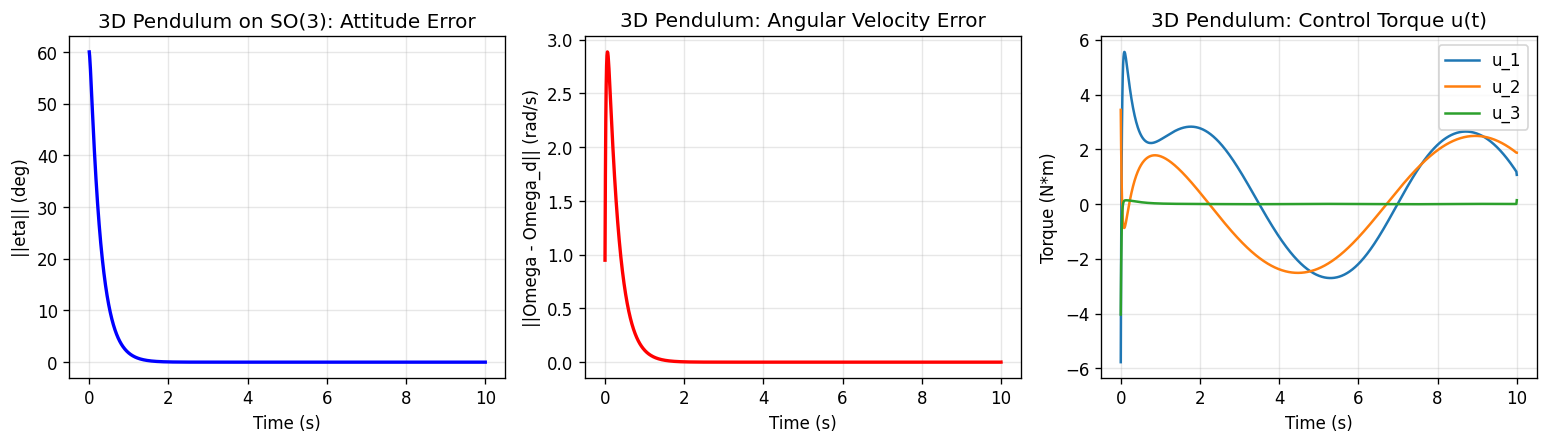

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].plot(t_sim_3d, att_err_3d, 'b-', lw=2)
axes[0].set_title('3D Pendulum on SO(3): Attitude Error')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('||eta|| (deg)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(t_sim_3d, vel_err_3d, 'r-', lw=2)
axes[1].set_title('3D Pendulum: Angular Velocity Error')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('||Omega - Omega_d|| (rad/s)')
axes[1].grid(True, alpha=0.3)

axes[2].plot(t_sim_3d, u_hist_3d[:, 0], label='u_1')
axes[2].plot(t_sim_3d, u_hist_3d[:, 1], label='u_2')
axes[2].plot(t_sim_3d, u_hist_3d[:, 2], label='u_3')
axes[2].set_title('3D Pendulum: Control Torque u(t)')
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('Torque (N*m)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
